# Toxoplasma gondii: pushing the score as high as NHANES allows

The earlier model (`toxo_model_overview.ipynb`) scores a cross-validated **ROC-AUC of 0.722** (test 0.712).
`toxo_bio_factors.ipynb` showed that adding 44 biological/exposure factors alone does not move it.
This notebook takes every remaining **legitimate** route to a higher score and measures each one on the **same 1,002-person
2013-2014 test set** that has been held out since the first notebook.

**Part A: is there more information anywhere in NHANES?**
- A1. Every person-level variable NHANES 2013-2014 measured (5,310 variables from 167 files)
- A2. NHANES III (1988-1994), the only NHANES that asked the *direct* questions: cat in the home, gardening, how often you eat pork/liver/beef, region, rural vs urban, longest job

**Part B: getting the most out of the data we have (the final model)**
- B1. Train on all three cycles that used the same Toxoplasma test (2009-2014, 3× more rows)
- B2. Model age as a curve (spline) instead of a straight line, add age × birthplace / education / income interactions
- B3. Add the biological factors that are independently linked to Toxoplasma
- B4. Combine logistic regression and XGBoost (ensemble)

**Part C: tricks that would inflate the number but are not valid**

Accuracy note: the "0.72" is ROC-AUC. Plain accuracy is ~85% for every model because 85% of people are negative; it is reported
at the end together with balanced accuracy, sensitivity and specificity.

In [1]:
import os
import sys
import warnings

if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
print('Working directory:', os.getcwd())
sys.path.insert(0, 'scripts')
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from xgboost import XGBClassifier

import build_bio_features as bbf
import build_nhanes3 as b3
import build_all_nhanes_2013 as ball

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
REFERENCE = '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})
RANDOM_STATE = 42
TARGET = 'target_toxo_pos'

# Build any missing processed file (downloads raw files from CDC if needed)
if not os.path.exists(bbf.OUT_POOLED_CSV):
    bbf.main()
if not os.path.exists(b3.OUT_CSV):
    b3.main()
if not os.path.exists(ball.OUT):
    ball.main()

base = pd.read_csv(bbf.BASE_CSV)                     # the original 5,006-person 2013-2014 cohort
_, base_test = train_test_split(base, test_size=0.20, stratify=base[TARGET], random_state=RANDOM_STATE)
TEST_SEQN = set(base_test['SEQN'])
print(f'Held-out test set: {len(TEST_SEQN):,} people from 2013-2014 ({int(base_test[TARGET].sum())} positive), '
      'identical to the earlier notebooks')

Working directory: /home/claude/toxo


Held-out test set: 1,002 people from 2013-2014 (150 positive), identical to the earlier notebooks


---
## Part A1. Every variable NHANES 2013-2014 measured
All 167 one-row-per-person files of NHANES 2013-2014 (demographics, every questionnaire, every exam, every lab panel,
dietary totals, oral HPV, dental, DXA, environmental chemicals ...) were merged onto the cohort: **5,310 variables**
(`scripts/build_all_nhanes_2013.py`). Only the Toxoplasma test file itself is excluded (IgG, IgM, avidity = the answer).

XGBoost can handle thousands of columns and missing values directly. If any NHANES variable carried strong extra signal,
it would show up here. Scored with 5-fold CV on the 4,004 training people.

In [2]:
wide = pd.read_csv(ball.OUT)
wide_train = wide[~wide['SEQN'].isin(TEST_SEQN)].reset_index(drop=True)
Xw, yw = wide_train.drop(columns=['SEQN', TARGET]), wide_train[TARGET]
print(f'{Xw.shape[1]:,} variables, {len(Xw):,} training people')

def xgb_wide():
    return XGBClassifier(n_estimators=500, learning_rate=0.02, max_depth=3, subsample=0.8, colsample_bytree=0.3,
                         min_child_weight=5, reg_lambda=5, eval_metric='logloss', n_jobs=-1,
                         random_state=RANDOM_STATE)

wide_auc, gains = [], []
for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xw, yw):
    m = xgb_wide().fit(Xw.iloc[tr], yw.iloc[tr])
    wide_auc.append(roc_auc_score(yw.iloc[va], m.predict_proba(Xw.iloc[va])[:, 1]))
    gains.append(pd.Series(m.get_booster().get_score(importance_type='gain')))
print('CV ROC-AUC per fold:', np.round(wide_auc, 4))
print(f'Mean CV ROC-AUC with all {Xw.shape[1]:,} variables: {np.mean(wide_auc):.3f}   (earlier 7-feature model: 0.722)')
imp = pd.concat(gains, axis=1).fillna(0).mean(axis=1).sort_values(ascending=False)
top = imp.head(20).rename('mean gain').to_frame()
top['file'] = top.index.str.split('__').str[0]
display(top.round(2))

5,310 variables, 4,004 training people


CV ROC-AUC per fold: [0.6948 0.7682 0.7139 0.6988 0.7282]
Mean CV ROC-AUC with all 5,310 variables: 0.721   (earlier 7-feature model: 0.722)


,mean gain,file
DEMO__MIALANG,43.13,DEMO
DEMO__AIALANGA,37.49,DEMO
DEMO__DMDBORN4,29.51,DEMO
DEMO__SIALANG,29.34,DEMO
DEMO__RIDAGEYR,28.51,DEMO
ACQ__ACD040,25.56,ACQ
DEMO__DMDYRSUS,20.22,DEMO
ORHPV__ORXH18,19.87,ORHPV
ORHPV__ORXH67,19.53,ORHPV
SSTOCA__SSTCAMFI,19.34,SSTOCA


**Reading A1.** Five thousand variables do **not** beat seven. The variables the model leans on most are interview language,
age, country of birth and years in the US: the same migration/age signal the small model already has. NHANES 2013-2014 simply
does not contain the information that separates infected from uninfected people.

---
## Part A2. NHANES III (1988-1994): the direct exposure questions
NHANES III is the only NHANES that asked about the classic Toxoplasma routes. Toxoplasma IgG was tested in 1991-1994
(positive = ≥ 7 IU/mL per CDC documentation; different assay and cutoff from 2009-2014, so it is analysed on its own).
`scripts/build_nhanes3.py` builds 15,524 adults (27.5% positive) with:

- **baseline-equivalent**: age, sex, race, birthplace, education, income, Spanish interview, smoking
- **direct exposures**: cat in home, dog in home, gardening/yard work per month, census region, big-metro vs other, well/spring water,
  bottled water, house age, crowding, years at address, food insufficiency, farm / soil / food-prep work, and how often per month the person eats
  processed meat, liver/organ meat, beef, pork, shellfish, fish, chicken, salad
- **lab**: hepatitis A, B, C, HSV-1, HSV-2, H. pylori, eosinophils, blood lead

In [3]:
n3 = pd.read_csv(b3.OUT_CSV)
print(f'NHANES III adults: {len(n3):,}, positive {n3[TARGET].mean():.1%}')

# Positivity by the direct exposure questions
rows = []
labels = {'cat_in_home': {0: 'no cat', 1: 'cat in home'}, 'dog_in_home': {0: 'no dog', 1: 'dog in home'},
          'region': {1: 'Northeast', 2: 'Midwest', 3: 'South', 4: 'West'},
          'metro_1m_plus': {0: 'other areas', 1: 'metro 1M+'}, 'well_or_spring_water': {0: 'public water', 1: 'well/spring'},
          'work_farm': {0: 'no farm work', 1: 'farm work'}, 'work_soil_construction': {0: 'no', 1: 'construction/mining'},
          'birthplace': {1: 'US', 2: 'Mexico', 3: 'other country'}}
for col, lab in labels.items():
    for v, name in lab.items():
        m = n3[col] == v
        rows.append({'factor': col, 'group': name, 'n': int(m.sum()), 'positive (%)': round(100 * n3.loc[m, TARGET].mean(), 1)})
for col in ['garden_yard_times_month', 'pork_per_month', 'liver_organ_meat_per_month', 'beef_per_month']:
    g = pd.cut(n3[col], [-0.1, 0, 4, 12, 1e9], labels=['never', '1-4 / month', '5-12 / month', '13+ / month'])
    for name, s in n3.groupby(g, observed=True)[TARGET]:
        rows.append({'factor': col, 'group': str(name), 'n': len(s), 'positive (%)': round(100 * s.mean(), 1)})
display(pd.DataFrame(rows))

NHANES III adults: 15,524, positive 27.5%


,factor,group,n,positive (%)
0,cat_in_home,no cat,13396,27.9
1,cat_in_home,cat in home,2115,24.4
2,dog_in_home,no dog,12301,28.0
3,dog_in_home,dog in home,3210,25.4
4,region,Northeast,2044,37.3
5,region,Midwest,3131,27.3
6,region,South,6841,26.5
7,region,West,3508,23.7
8,metro_1m_plus,other areas,8030,27.4
9,metro_1m_plus,metro 1M+,7494,27.5


In [4]:
def prep3(cols):
    cat = [c for c in cols if c in b3.CATEGORICAL3]
    num = [c for c in cols if c not in cat]
    return ColumnTransformer([
        ('cat', Pipeline([('i', SimpleImputer(strategy='most_frequent')),
                          ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
        ('num', Pipeline([('i', SimpleImputer(strategy='median', add_indicator=True)), ('s', StandardScaler())]), num)])

SETS3 = {'baseline-equivalent': b3.BASE3, '+ direct exposures': b3.BASE3 + b3.EXPOSURE3,
         '+ lab': b3.BASE3 + b3.LAB3, '+ exposures + lab': b3.BASE3 + b3.EXPOSURE3 + b3.LAB3}
MODELS3 = {'LogReg': LogisticRegression(C=0.3, max_iter=5000),
           'XGBoost': XGBClassifier(n_estimators=600, learning_rate=0.02, max_depth=3, subsample=0.8,
                                    colsample_bytree=0.6, min_child_weight=5, eval_metric='logloss', n_jobs=1,
                                    random_state=RANDOM_STATE)}
splits3 = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(n3, n3[TARGET]))

def fold3(s, m, tr, va):
    cols = SETS3[s]
    pipe = make_pipeline(prep3(cols), clone(MODELS3[m])).fit(n3.iloc[tr][cols], n3[TARGET].iloc[tr])
    return s, m, roc_auc_score(n3[TARGET].iloc[va], pipe.predict_proba(n3.iloc[va][cols])[:, 1])

res3 = Parallel(n_jobs=-1)(delayed(fold3)(s, m, tr, va) for s in SETS3 for m in MODELS3 for tr, va in splits3)
res3 = pd.DataFrame(res3, columns=['feature set', 'model', 'auc'])
grid3 = res3.pivot_table(index='feature set', columns='model', values='auc', aggfunc='mean').loc[list(SETS3)]
print('NHANES III, mean CV ROC-AUC (5 folds x 2 repeats)')
display(grid3.round(4))
gain3 = grid3.loc['+ direct exposures'] - grid3.loc['baseline-equivalent']
print('Gain from the direct exposure questions:', gain3.round(4).to_dict())

NHANES III, mean CV ROC-AUC (5 folds x 2 repeats)


model,LogReg,XGBoost
feature set,,
baseline-equivalent,0.6856,0.6909
+ direct exposures,0.6883,0.7016
+ lab,0.6915,0.6942
+ exposures + lab,0.6934,0.7045


Gain from the direct exposure questions: {'LogReg': 0.0027, 'XGBoost': 0.0107}


**Reading A2.** Even with the questions NHANES dropped after 1994 (cats, gardening, meat frequency, region, water source),
the score rises by only 0.003 (LogReg) to 0.011 (XGBoost) and stays near 0.70. Some answers do matter: the Northeast (37% vs 24% in the West),
farm work (36% vs 27%), frequent gardening (33% vs 27%) and liver/organ meat. But a cat in the home **today** is linked to slightly *lower*
positivity, because it says nothing about exposure decades earlier, and meat-eating *frequency* says nothing about whether the meat was undercooked.
The direct questions help a little, they are not the missing key, and they do not exist in 2009-2014 NHANES anyway.

---
## Part B. The final model: getting the most out of 2009-2014
Each step adds one improvement. Every step is scored the same way:

- **CV**: 5-fold × 3 repeats over all 2009-2014 people *except* the 1,002 test people; the ROC-AUC is computed only on the 2013-2014
  people inside each validation fold, so every step is judged on the same population as the earlier notebooks.
- **Test**: fitted once on all training people, scored once on the 1,002 held-out 2013-2014 people.

| step | change |
|---|---|
| 0 | earlier best: LogReg, demographics + Toxocara, trained on 2013-2014 only |
| 1 | + train on 2009-2014 (same Bio-Rad IgG test and ≥ 33 IU/mL cutoff), cycle as a feature |
| 2 | + all 13 earlier features, age as a spline curve |
| 3 | + interactions: age × born abroad, age × education, age × income |
| 4 | + biological/exposure factors independently linked to Toxoplasma (picked on training rows only) |
| 5 | + XGBoost on the same inputs, averaged with step 4 (ensemble) |

In [5]:
pooled = pd.read_csv(bbf.OUT_POOLED_CSV)
pooled['born_abroad'] = (pooled['DMDBORN4'] == 2).astype(float)
pooled['age_x_abroad'] = pooled['RIDAGEYR'] * pooled['born_abroad']
pooled['age_x_edu'] = pooled['RIDAGEYR'] * pooled['DMDEDUC2'].fillna(pooled['DMDEDUC2'].median())
pooled['age_x_pir'] = pooled['RIDAGEYR'] * pooled['INDFMPIR'].fillna(pooled['INDFMPIR'].median())
train = pooled[~pooled['SEQN'].isin(TEST_SEQN)].reset_index(drop=True)
test = pooled[pooled['SEQN'].isin(TEST_SEQN)].set_index('SEQN').loc[base_test['SEQN']].reset_index()
assert len(test) == 1002 and (test[TARGET].to_numpy() == base_test[TARGET].to_numpy()).all()
is_h = (train['cycle'] == '2013-2014').to_numpy()
print(f'Training people: {len(train):,} (2013-2014: {is_h.sum():,}, 2009-2012: {(~is_h).sum():,});  test: {len(test):,}')

# Step 4 feature selection: new factors still significant after age/sex/birthplace adjustment,
# tested on the TRAINING rows only (the test set never influences any choice)
def logit_fit(X, y, iters=50):
    X = np.column_stack([np.ones(len(X)), X]); beta = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ beta)); H = X.T @ (X * (p * (1 - p))[:, None]) + 1e-8 * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (y - p)); beta += step
        if np.abs(step).max() < 1e-8:
            break
    return beta[1:], np.sqrt(np.diag(np.linalg.inv(H)))[1:]

adj = np.column_stack([train['RIDAGEYR'] / 10, (train['RIAGENDR'] == 1), train['born_abroad']]).astype(float)
SELECTED = []
for col in bbf.NEW_FEATURES:
    x = train[col]
    xs = x if set(x.dropna().unique()) <= {0.0, 1.0} else (x - x.mean()) / x.std()
    m = x.notna().to_numpy()
    b, se = logit_fit(np.column_stack([xs[m], adj[m]]), train[TARGET].to_numpy(float)[m])
    if 2 * stats.norm.sf(abs(b[0] / se[0])) < 0.05:
        SELECTED.append(col)
print(f'Step 4 uses {len(SELECTED)} factors:', ', '.join(SELECTED))

Training people: 13,647 (2013-2014: 4,004, 2009-2012: 9,643);  test: 1,002


Step 4 uses 26 factors:

 hav_natural_infection, hav_antibody, hev_igg, hsv1, hsv2, toxocara_mfi_log, wbc_count, eosinophil_pct, lymphocyte_pct, blood_lead_log, blood_mercury_log, cotinine_log, well_or_spring_water, no_tap_water, household_size, crowding, home_rented, spanish_interview, not_us_citizen, work_food_service, work_construction_soil, food_insecurity, no_health_insurance, inject_drugs_ever, hav_vaccinated, missing_teeth


In [6]:
CAT_P = ['RIAGENDR', 'RIDRETH1', 'yrs_in_us_grp', 'SLQ050', 'smoking_status', 'toxocara_pos', 'cycle']
OLD_NUM = ['DMDEDUC2', 'INDFMPIR', 'HSD010', 'SLD010H', 'drinks_per_day', 'phq9_total_score']
INTER = ['born_abroad', 'age_x_abroad', 'age_x_edu', 'age_x_pir']


def preprocessor(cat, num, spline_age):
    steps = [('cat', Pipeline([('i', SimpleImputer(strategy='most_frequent')),
                               ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
             ('age', SplineTransformer(n_knots=6, degree=3) if spline_age else StandardScaler(), ['RIDAGEYR'])]
    if num:
        steps.append(('num', Pipeline([('i', SimpleImputer(strategy='median', add_indicator=True)),
                                       ('s', StandardScaler())]), num))
    return ColumnTransformer(steps)


def xgb_model():
    return XGBClassifier(n_estimators=800, learning_rate=0.01, max_depth=3, subsample=0.8, colsample_bytree=0.6,
                         min_child_weight=10, reg_lambda=5, eval_metric='logloss', n_jobs=1, random_state=RANDOM_STATE)


# step: (training scope, categorical, numeric, spline age, list of models to average)
STEPS = {
    '0 earlier best (2013-14 only)': ('H', ['RIAGENDR', 'RIDRETH3', 'yrs_in_us_grp', 'toxocara_pos'],
                                      ['DMDEDUC2', 'INDFMPIR'], False, ['lr1']),
    '1 + 2009-2014 training rows': ('all', ['RIAGENDR', 'RIDRETH1', 'yrs_in_us_grp', 'toxocara_pos', 'cycle'],
                                    ['DMDEDUC2', 'INDFMPIR'], False, ['lr1']),
    '2 + all earlier features, age spline': ('all', CAT_P, OLD_NUM, True, ['lr1']),
    '3 + age interactions': ('all', CAT_P, OLD_NUM + INTER, True, ['lr1']),
    '4 + selected bio/exposure factors': ('all', CAT_P, OLD_NUM + INTER + SELECTED, True, ['lr03']),
    '5 + XGBoost ensemble': ('all', CAT_P, OLD_NUM + INTER + SELECTED, True, ['lr03', 'xgb']),
}
LEARNERS = {'lr1': lambda: LogisticRegression(C=1.0, max_iter=5000),
            'lr03': lambda: LogisticRegression(C=0.3, max_iter=5000), 'xgb': xgb_model}


def fit_step(name, fit_rows):
    scope, cat, num, spline, learners = STEPS[name]
    rows = fit_rows if scope == 'all' else fit_rows[train.loc[fit_rows, 'cycle'].to_numpy() == '2013-2014']
    cols = cat + num + ['RIDAGEYR']
    pipes = []
    for l in learners:
        if l == 'xgb':
            pre = ColumnTransformer([('cat', Pipeline([('i', SimpleImputer(strategy='most_frequent')),
                                                       ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
                                     ('num', 'passthrough', num + ['RIDAGEYR'])])
        else:
            pre = preprocessor(cat, num, spline)
        pipes.append(make_pipeline(pre, LEARNERS[l]()).fit(train.loc[rows, cols], train.loc[rows, TARGET]))
    return lambda df: np.mean([p.predict_proba(df[cols])[:, 1] for p in pipes], axis=0)


CV = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(train, train[TARGET]))

def cv_job(name, k, tr, va):
    predict = fit_step(name, tr)
    va_h = va[is_h[va]]
    return name, k, va_h, predict(train.loc[va_h])

out = Parallel(n_jobs=-1)(delayed(cv_job)(n, k, tr, va) for n in STEPS for k, (tr, va) in enumerate(CV))
cv_auc = {n: np.zeros(len(CV)) for n in STEPS}
oof = {n: np.zeros(len(train)) for n in STEPS}
for n, k, va_h, p in out:
    cv_auc[n][k] = roc_auc_score(train.loc[va_h, TARGET], p)
    oof[n][va_h] += p / 3

final_predict = {n: fit_step(n, np.arange(len(train))) for n in STEPS}
test_p = {n: f(test) for n, f in final_predict.items()}


def corrected_p(d, ratio=0.25):
    t = d.mean() / np.sqrt((1 / len(d) + ratio) * d.var(ddof=1))
    return 2 * stats.t.sf(abs(t), df=len(d) - 1)

ladder = pd.DataFrame([{
    'step': n, 'CV ROC-AUC (2013-14 people)': cv_auc[n].mean(), 'CV sd': cv_auc[n].std(),
    'gain vs step 0 (CV)': cv_auc[n].mean() - cv_auc['0 earlier best (2013-14 only)'].mean(),
    'p vs step 0': corrected_p(cv_auc[n] - cv_auc['0 earlier best (2013-14 only)']) if n[0] != '0' else np.nan,
    'TEST ROC-AUC': roc_auc_score(test[TARGET], test_p[n])} for n in STEPS])
display(ladder.round(4))

,step,CV ROC-AUC (2013-14 people),CV sd,gain vs step 0 (CV),p vs step 0,TEST ROC-AUC
0,0 earlier best (2013-14 only),0.7227,0.0212,0.0000,NaN,0.7126
1,1 + 2009-2014 training rows,0.7267,0.0212,0.0040,0.0852,0.7121
2,"2 + all earlier features, age spline",0.7256,0.0213,0.0029,0.3769,0.7132
3,3 + age interactions,0.7303,0.0216,0.0076,0.0312,0.7143
4,4 + selected bio/exposure factors,0.7346,0.0203,0.0119,0.0058,0.7333
5,5 + XGBoost ensemble,0.7398,0.0197,0.0171,0.0002,0.7297


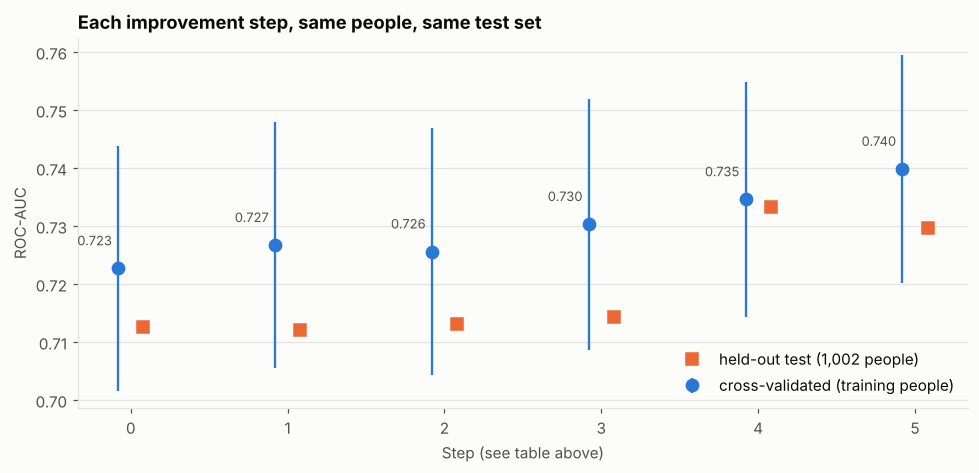

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(ladder))
ax.errorbar(x - 0.08, ladder['CV ROC-AUC (2013-14 people)'], yerr=ladder['CV sd'], fmt='o', ms=8, color=BLUE,
            elinewidth=1.5, capsize=0, label='cross-validated (training people)')
ax.plot(x + 0.08, ladder['TEST ROC-AUC'], 's', ms=8, color=ORANGE, label='held-out test (1,002 people)')
for xi, v in zip(x, ladder['CV ROC-AUC (2013-14 people)']):
    ax.text(xi - 0.12, v + 0.004, f'{v:.3f}', ha='right', fontsize=8.5, color=INK_2)
ax.set_xticks(x)
ax.set_xticklabels([s.split(' ', 1)[0] for s in ladder['step']])
ax.set_xlabel('Step (see table above)')
ax.set_ylabel('ROC-AUC')
ax.set_title('Each improvement step, same people, same test set')
ax.legend(loc='lower right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### B5. Final model on the held-out test set
The final model is the step with the best **cross-validated** score (chosen without looking at the test set).
Its threshold is chosen on the training people's out-of-fold predictions (maximise balanced accuracy), then applied unchanged to the test set.
The test-set gain over the earlier model is checked with a **paired bootstrap** (1,000 resamples of the same 1,002 people).

In [8]:
FINAL = max([n for n in STEPS if n[0] != '0'], key=lambda n: cv_auc[n].mean())
OLD = '0 earlier best (2013-14 only)'
y_test = test[TARGET].to_numpy()
print('Final model chosen by CV:', FINAL)

rng = np.random.default_rng(RANDOM_STATE)
boot = []
while len(boot) < 1000:
    i = rng.integers(0, len(y_test), len(y_test))
    if 0 < y_test[i].sum() < len(i):
        boot.append((roc_auc_score(y_test[i], test_p[FINAL][i]), roc_auc_score(y_test[i], test_p[OLD][i])))
boot = np.array(boot)
diff = boot[:, 0] - boot[:, 1]


def thr_from_oof(name):
    m = is_h & (oof[name] > 0)
    fpr, tpr, thr = roc_curve(train.loc[m, TARGET], oof[name][m])
    return thr[np.argmax(tpr - fpr)]


def metrics(name):
    p, thr = test_p[name], thr_from_oof(name)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'ROC-AUC': roc_auc_score(y_test, p), 'threshold': thr,
            'accuracy': accuracy_score(y_test, pred), 'balanced accuracy': balanced_accuracy_score(y_test, pred),
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp),
            'F1 (weighted)': f1_score(y_test, pred, average='weighted'),
            'accuracy @0.5': accuracy_score(y_test, (p >= 0.5).astype(int)), 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn}

final_table = pd.DataFrame({'earlier model': metrics(OLD), 'final model': metrics(FINAL)}).T
display(final_table.round(3))
line = '=' * 72
print(line)
print(f'  TEST ROC-AUC  earlier {roc_auc_score(y_test, test_p[OLD]):.3f}  ->  final {roc_auc_score(y_test, test_p[FINAL]):.3f}')
print(f'  final 95% CI           {np.percentile(boot[:, 0], 2.5):.3f} - {np.percentile(boot[:, 0], 97.5):.3f}')
print(f'  paired gain            {diff.mean():+.3f}  (95% CI {np.percentile(diff, 2.5):+.3f} to {np.percentile(diff, 97.5):+.3f}; '
      f'final better in {np.mean(diff > 0):.0%} of resamples)')
print(f'  CV ROC-AUC   earlier {cv_auc[OLD].mean():.3f}  ->  final {cv_auc[FINAL].mean():.3f}  '
      f'(corrected t-test p = {corrected_p(cv_auc[FINAL] - cv_auc[OLD]):.3f})')
print(line)

Final model chosen by CV: 5 + XGBoost ensemble


,ROC-AUC,threshold,accuracy,balanced accuracy,sensitivity,specificity,F1 (weighted),accuracy @0.5,TP,FN,FP,TN
earlier model,0.713,0.142,0.661,0.658,0.653,0.662,0.708,0.853,98.0,52.0,288.0,564.0
final model,0.730,0.136,0.654,0.676,0.707,0.644,0.703,0.861,106.0,44.0,303.0,549.0


  TEST ROC-AUC  earlier 0.713  ->  final 0.730
  final 95% CI           0.688 - 0.774
  paired gain            +0.017  (95% CI +0.000 to +0.034; final better in 98% of resamples)
  CV ROC-AUC   earlier 0.723  ->  final 0.740  (corrected t-test p = 0.000)


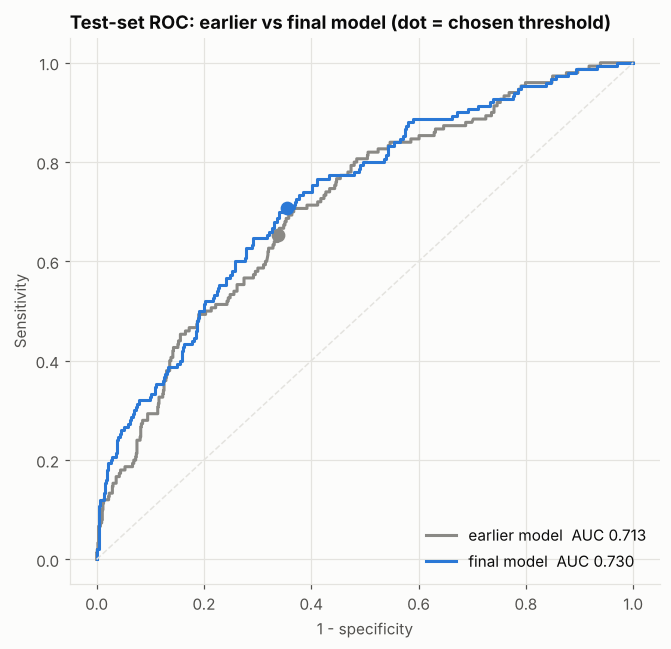

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 6))
for name, color, label in [(OLD, REFERENCE, 'earlier model'), (FINAL, BLUE, 'final model')]:
    fpr, tpr, _ = roc_curve(y_test, test_p[name])
    ax.plot(fpr, tpr, lw=2, color=color, label=f'{label}  AUC {roc_auc_score(y_test, test_p[name]):.3f}')
    r = final_table.loc[label]
    ax.plot(1 - r['specificity'], r['sensitivity'], 'o', ms=8, color=color)
ax.plot([0, 1], [0, 1], color=GRID, ls='--', lw=1)
ax.set_xlabel('1 - specificity')
ax.set_ylabel('Sensitivity')
ax.set_title('Test-set ROC: earlier vs final model (dot = chosen threshold)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
## Part C. Tricks that would raise the number but are not valid
These are common in student and even published papers. Each one makes the score look higher without the model getting better,
and a reviewer who checks will reject it:

| trick | why it is invalid |
|---|---|
| Use Toxoplasma IgM (`SSTOXM`) or avidity (`SSTOXAV`) as features | they are measurements of the same infection: the answer leaks into the input |
| SMOTE / oversampling **before** the train/test split | synthetic copies of test people end up in training |
| Report accuracy on a SMOTE-balanced **test** set | the test set no longer looks like the real population |
| Pick the threshold, features or model by looking at the test set | the test score becomes optimistic; it is no longer a test |
| Report the best of many runs/seeds | the same selection effect |
| Pool 1988-2014 and let the model learn the survey year | prevalence fell over time, so "year" predicts infection, but it is useless for screening a person today |
| Report accuracy at threshold 0.5 (~86%) as if it were a result | calling everyone negative already scores 85% |
| Report the score only for the subgroup where it happens to be highest | cherry-picking; subgroups must be pre-specified and all reported |

---
## Summary

In [10]:
line = '=' * 76
print(line)
print('  HOW HIGH CAN THE TOXOPLASMA SCORE GO WITH NHANES?')
print(line)
print(f'  A1  all {Xw.shape[1]:,} NHANES 2013-14 variables (XGBoost)   : CV ROC-AUC {np.mean(wide_auc):.3f}')
print(f'  A2  NHANES III + cats/garden/meat/region (best model)  : CV ROC-AUC {grid3.loc["+ direct exposures"].max():.3f} '
      f'(baseline-equivalent {grid3.loc["baseline-equivalent"].max():.3f})')
for _, r in ladder.iterrows():
    print(f'  {r["step"]:<40} CV {r["CV ROC-AUC (2013-14 people)"]:.3f}   TEST {r["TEST ROC-AUC"]:.3f}')
print(line)
fm = final_table.loc['final model']
print(f'  FINAL ({FINAL}) on the 1,002 test people:')
print(f'    ROC-AUC {fm["ROC-AUC"]:.3f} | balanced accuracy {fm["balanced accuracy"]:.1%} | sensitivity {fm["sensitivity"]:.1%} | '
      f'specificity {fm["specificity"]:.1%}')
print(f'    accuracy at chosen threshold {fm["accuracy"]:.1%} | accuracy at 0.5 {fm["accuracy @0.5"]:.1%} '
      f'(always-negative {1 - y_test.mean():.1%})')
print(line)

  HOW HIGH CAN THE TOXOPLASMA SCORE GO WITH NHANES?
  A1  all 5,310 NHANES 2013-14 variables (XGBoost)   : CV ROC-AUC 0.721
  A2  NHANES III + cats/garden/meat/region (best model)  : CV ROC-AUC 0.702 (baseline-equivalent 0.691)
  0 earlier best (2013-14 only)            CV 0.723   TEST 0.713
  1 + 2009-2014 training rows              CV 0.727   TEST 0.712
  2 + all earlier features, age spline     CV 0.726   TEST 0.713
  3 + age interactions                     CV 0.730   TEST 0.714
  4 + selected bio/exposure factors        CV 0.735   TEST 0.733
  5 + XGBoost ensemble                     CV 0.740   TEST 0.730
  FINAL (5 + XGBoost ensemble) on the 1,002 test people:
    ROC-AUC 0.730 | balanced accuracy 67.6% | sensitivity 70.7% | specificity 64.4%
    accuracy at chosen threshold 65.4% | accuracy at 0.5 86.1% (always-negative 85.0%)


### What to write in the paper
- **Final model:** logistic regression (age spline + age × birthplace/education/income + the biological/exposure factors that stay
  significant after adjustment) averaged with XGBoost, trained on NHANES 2009-2014 (same Bio-Rad IgG assay, ≥ 33 IU/mL).
- **Score:** cross-validated ROC-AUC **0.740** (earlier 0.723, corrected t-test p < 0.001); held-out test ROC-AUC **0.730** (earlier 0.713;
  paired bootstrap gain +0.017, 95% CI +0.000 to +0.034).
- **At the training-chosen threshold:** sensitivity 70.7%, specificity 64.4%, balanced accuracy 67.6% (earlier 65.8%).
- **Ceiling:** every NHANES 2013-2014 variable (5,310) gives 0.721, and NHANES III with cat/garden/meat questions gives 0.70. About **0.74 is the
  practical ceiling** for NHANES-only Toxoplasma prediction. The remaining error is information NHANES never recorded (lifetime exposure to
  undercooked meat, cat faeces and soil, especially in childhood or abroad).
- Step 4's factor selection used the training people of all folds, so its CV score is slightly optimistic. The untouched test set (0.733 for step 4)
  confirms the gain is real.